# Unified Bangla — mBART-50 Cross-Dialectal Translation

## 1. Setup

### 1.1 Install dependencies

In [1]:
# Kaggle-safe installs: no dependency resolver conflicts
!pip -q install --no-deps protobuf==3.20.3
!pip -q install --no-deps portalocker==2.8.2
!pip -q install --no-deps rapidfuzz==3.5.2
!pip -q install --no-deps jiwer==3.0.1
!pip -q install --no-deps sacrebleu==2.4.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 2.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 31.1 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 1.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.3/106.3 kB 2.5 MB/s eta 0:00:00a 0:00:01


### 1.2 Imports and device

In [2]:
import os, gc, json, glob, shutil, time, threading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset as TorchDataset, DataLoader
from transformers import MBartForConditionalGeneration, MBart50TokenizerFast, get_linear_schedule_with_warmup

from sacrebleu import corpus_bleu, corpus_chrf
from jiwer import wer, cer
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### 1.3 Configuration

In [3]:
MODEL_NAME = "facebook/mbart-large-50-many-to-many-mmt"
SRC_LANG = "bn_IN"
TGT_LANG = "bn_IN"

# 6 dialects (standard Bangla is std_bn)
DIALECT_MAP = {
    "std_bn": "bangla_speech",
    "barishal": "barishal_bangla_speech",
    "chittagong": "chittagong_bangla_speech",
    "mymensingh": "mymensingh_bangla_speech",
    "noakhali": "noakhali_bangla_speech",
    "sylhet": "sylhet_bangla_speech",
}
DIALECTS = list(DIALECT_MAP.keys())

# Target control tags added to the tokenizer
TARGET_TAGS = [f"<2{d}>" for d in DIALECTS]

# Sequence lengths
MAX_SOURCE_LEN = 96
MAX_TARGET_LEN = 96

# Training
BATCH_SIZE = 8
LR = 3e-5
EPOCHS = 3
WARMUP_RATIO = 0.1

# Evaluation (lower EVAL_BATCH_SIZE / NUM_BEAMS if you hit OOM)
EVAL_BATCH_SIZE = 8
NUM_BEAMS = 4

# Paths
WORKDIR = "/kaggle/working"
BEST_PATH = f"{WORKDIR}/mbart50_best"
HISTORY_CSV = f"{WORKDIR}/metrics_history.csv"
HISTORY_JSON = f"{WORKDIR}/metrics_history.json"

METRIC_NAMES = ["bleu", "chrf", "wer", "cer"]

print("Dialects:", DIALECTS)
print("Target tags:", TARGET_TAGS)

Dialects: ['std_bn', 'barishal', 'chittagong', 'mymensingh', 'noakhali', 'sylhet']
Target tags: ['<2std_bn>', '<2barishal>', '<2chittagong>', '<2mymensingh>', '<2noakhali>', '<2sylhet>']


### 1.4 GPU memory helper

In [4]:
def clear_gpu(*names):
    # Drop named globals (e.g. "model", "optimizer") then free the cache
    for name in names:
        if name in globals():
            del globals()[name]

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

clear_gpu()
print("✅ GPU cleared")

✅ GPU cleared


## 2. Data

### 2.1 Locate the dataset files

In [5]:
def find_file_in_kaggle_input(filename: str):
    root = "/kaggle/input/datasets/tasfiaisrat/unified-bangla-qpain"
    for dirpath, _, files in os.walk(root):
        if filename in files and "Unified Bangla Dataset" in dirpath:
            return os.path.join(dirpath, filename)
    # fallback: search anywhere under /kaggle/input
    for dirpath, _, files in os.walk(root):
        if filename in files:
            return os.path.join(dirpath, filename)
    return None

train_path = find_file_in_kaggle_input("Unified_train_dataset.csv")
val_path   = find_file_in_kaggle_input("Unified_validation_dataset.csv")
test_path  = find_file_in_kaggle_input("Unified_test_dataset.csv")

print("Train:", train_path)
print("Val  :", val_path)
print("Test :", test_path)

assert train_path and val_path and test_path, "Could not find one or more CSV files under /kaggle/input"

Train: /kaggle/input/datasets/tasfiaisrat/unified-bangla-qpain/Unified_train_dataset.csv
Val  : /kaggle/input/datasets/tasfiaisrat/unified-bangla-qpain/Unified_validation_dataset.csv
Test : /kaggle/input/datasets/tasfiaisrat/unified-bangla-qpain/Unified_test_dataset.csv


### 2.2 Load the raw splits

In [6]:
train_df_raw = pd.read_csv(train_path)
val_df_raw   = pd.read_csv(val_path)
test_df_raw  = pd.read_csv(test_path)

print("Train rows:", len(train_df_raw))
print("Val rows  :", len(val_df_raw))
print("Test rows :", len(test_df_raw))
train_df_raw.head()

Train rows: 1875
Val rows  : 250
Test rows : 375


,bangla_speech,barishal_bangla_speech,chittagong_bangla_speech,mymensingh_bangla_speech,noakhali_bangla_speech,sylhet_bangla_speech
0,কেমন আছো ?,আসো কোরোহম?,কেন আচো?,কেমত আছো?,কেইক্কান আছেন ?,ভালা আছনি?
1,আজকে আমার মন ভালো নেই,আইজ মোর মনডা ভালোনা,আযিয়া আর মন বালা নাই?,আইজ আমার মন ভালা নাই,আইজ্জা আর মন ভালা নাই,আইজকু আমার মন ভালা নায়
2,তুমি কি করো ?,ও মোনু হর কি?,তুঁই কি গরো?,তুমি কিতা করো?,তুমি কিআ করর ?,তুমি কিতা খরো?
3,এই গরমে আমার কিছু ভালো লাগে না,এই থাডা পরা গরমে মোর কিস্সু ভাল্লাগেনা,এই গরমত আত্তুন কিচু বালা ন লাগের,এই গরমডাত আমার কিছু ভালা লাগে না,এতো গরমে আর কিচ্ছু ভালা লাগে না,অউ গরমো আমার কুনতা ভালা লাগের না
4,ছেলেটি সাদা রঙয়ের একটি শার্ট পরে এসেছিল,পলাউগ্গা এউক্কা ধলা রং এর এউক্কা গুন্জি পইর্রা...,ফোয়াইবা সাদা রংওর উজ্ঞা শার্ট ফরি আইস্যিল,ছেড়াটা সাদা রংগের একটা শার্ট পইড়া আইছিল,পোলাডা একটা সাদা রং এর শার্ট পড়ি আইসিলো,ফুয়াটায় এখটা সাদা রংগর শার্ট পিন্দিয়া আইছিল


### 2.3 Build dialect pairs

In [7]:
def build_pair_df(df_raw, src_key, tgt_key):
    src_col = DIALECT_MAP[src_key]
    tgt_col = DIALECT_MAP[tgt_key]

    if src_key == tgt_key:
        # identity pair: same column on both sides
        s = df_raw[src_col].dropna().astype(str).reset_index(drop=True)
        df = pd.DataFrame({"src": s, "tgt": s})
    else:
        df = df_raw[[src_col, tgt_col]].dropna().copy()
        df = df.rename(columns={src_col: "src", tgt_col: "tgt"}).reset_index(drop=True)
        df["src"] = df["src"].astype(str)
        df["tgt"] = df["tgt"].astype(str)

    df["src_dialect"] = src_key
    df["tgt_dialect"] = tgt_key
    return df


def build_all_pairs(df_raw, include_identity=False):
    rows = []
    for src_key in DIALECTS:
        for tgt_key in DIALECTS:
            if src_key == tgt_key and not include_identity:
                continue
            rows.append(build_pair_df(df_raw, src_key, tgt_key))
    return pd.concat(rows, ignore_index=True)


train_df = build_all_pairs(train_df_raw)
val_df   = build_all_pairs(val_df_raw)
test_df  = build_all_pairs(test_df_raw)

print("Train pairs:", len(train_df))
print("Val pairs  :", len(val_df))
print("Test pairs :", len(test_df))
train_df.head()

Train pairs: 56250
Val pairs  : 7500
Test pairs : 11250


,src,tgt,src_dialect,tgt_dialect
0,কেমন আছো ?,আসো কোরোহম?,std_bn,barishal
1,আজকে আমার মন ভালো নেই,আইজ মোর মনডা ভালোনা,std_bn,barishal
2,তুমি কি করো ?,ও মোনু হর কি?,std_bn,barishal
3,এই গরমে আমার কিছু ভালো লাগে না,এই থাডা পরা গরমে মোর কিস্সু ভাল্লাগেনা,std_bn,barishal
4,ছেলেটি সাদা রঙয়ের একটি শার্ট পরে এসেছিল,পলাউগ্গা এউক্কা ধলা রং এর এউক্কা গুন্জি পইর্রা...,std_bn,barishal


### 2.4 Tokenizer and target tags

In [8]:
tokenizer = MBart50TokenizerFast.from_pretrained(MODEL_NAME)
tokenizer.src_lang = SRC_LANG
tokenizer.tgt_lang = TGT_LANG
tokenizer.add_special_tokens({"additional_special_tokens": TARGET_TAGS})

print("Tokenizer size:", len(tokenizer))

tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

Tokenizer size: 250060


### 2.5 Dataset class

In [9]:
class DialectDataset(TorchDataset):
    def __init__(self, df, tokenizer, tag_mode="row", tgt_dialect=None,
                 max_src_len=MAX_SOURCE_LEN, max_tgt_len=MAX_TARGET_LEN):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.tag_mode = tag_mode
        self.tgt_dialect = tgt_dialect
        self.max_src_len = max_src_len
        self.max_tgt_len = max_tgt_len

    def __len__(self):
        return len(self.df)

    def _tag_for(self, idx):
        if self.tag_mode == "none":
            return ""

        if self.tag_mode == "fixed":
            d = self.tgt_dialect
        else:
            d = str(self.df.loc[idx, "tgt_dialect"])

        # guard against unexpected/empty dialect labels
        if d not in DIALECTS:
            d = "std_bn"  

        return f"<2{d}> "

    def __getitem__(self, idx):
        src_text = self._tag_for(idx) + str(self.df.loc[idx, "src"])
        tgt_text = str(self.df.loc[idx, "tgt"])

        model_inputs = self.tokenizer(
            src_text,
            max_length=self.max_src_len,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        # SAFER target encoding (no as_target_tokenizer)
        labels = self.tokenizer(
            text_target=tgt_text,
            max_length=self.max_tgt_len,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )["input_ids"]

        # Replace padding token id's of the labels by -100 so it's ignored by the loss
        labels[labels == self.tokenizer.pad_token_id] = -100

        return {
            "input_ids": model_inputs["input_ids"].squeeze(0),
            "attention_mask": model_inputs["attention_mask"].squeeze(0),
            "labels": labels.squeeze(0),
        }


def make_loader(df, tokenizer, batch_size=EVAL_BATCH_SIZE, shuffle=False, **kwargs):
    ds = DialectDataset(df, tokenizer, **kwargs)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

### 2.6 Dataloaders

In [10]:
train_loader = make_loader(train_df, tokenizer, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = make_loader(val_df, tokenizer, batch_size=BATCH_SIZE)
test_loader  = make_loader(test_df, tokenizer, batch_size=BATCH_SIZE)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches: 7032
Val batches  : 938
Test batches : 1407


## 3. Model and metrics

### 3.1 Model loader

In [11]:
def load_model(model_dir, resize=False, half=False, eval_mode=False):
    model = MBartForConditionalGeneration.from_pretrained(model_dir).to(device)
    tok = MBart50TokenizerFast.from_pretrained(model_dir)

    if resize:
        # tokenizer grew when the dialect tags were added
        tok.add_special_tokens({"additional_special_tokens": TARGET_TAGS})
        model.resize_token_embeddings(len(tok))

    tok.src_lang = SRC_LANG
    tok.tgt_lang = TGT_LANG
    model.generation_config.forced_bos_token_id = tok.convert_tokens_to_ids(TGT_LANG)
    model.config.forced_bos_token_id = None
    if eval_mode:
        model.eval()
    if half and device == "cuda":
        model.half()   # lower VRAM for evaluation only

    print("✅ Loaded from", model_dir, "| dtype:", next(model.parameters()).dtype, "| vocab:", len(tok))
    return model, tok

### 3.2 Metrics

In [12]:
def compute_metrics(preds, refs):
    # ---- GUARD: empty eval set ----
    if len(preds) == 0 or len(refs) == 0:
        return {"bleu": 0.0, "chrf": 0.0, "wer": 1.0, "cer": 1.0}

    # ---- BLEU / ChrF ----
    bleu = corpus_bleu(preds, [refs], tokenize="flores101").score
    chrf = corpus_chrf(preds, [refs]).score

    # ---- WER / CER (average per-sample) ----
    wer_scores, cer_scores = [], []
    for hyp, ref in zip(preds, refs):
        try:
            wer_scores.append(wer(ref, hyp))
        except Exception:
            wer_scores.append(1.0)
        try:
            cer_scores.append(cer(ref, hyp))
        except Exception:
            cer_scores.append(1.0)

    return {
        "bleu": float(bleu),
        "chrf": float(chrf),
        "wer": float(np.mean(wer_scores)),
        "cer": float(np.mean(cer_scores)),
    }

### 3.3 Generation and evaluation

In [13]:
@torch.no_grad()
def generate_preds(model, tokenizer, data_loader, num_beams=NUM_BEAMS,
                   max_gen_len=MAX_TARGET_LEN, max_batches=None, desc="Evaluating"):
    model.eval()
    preds, refs = [], []

    for bi, batch in enumerate(tqdm(data_loader, desc=desc, leave=False)):
        if max_batches is not None and bi >= max_batches:
            break

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        gen_ids = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=max_gen_len,
            num_beams=num_beams,
            length_penalty=1.0,
            no_repeat_ngram_size=3,      # helps reduce babbling
            repetition_penalty=1.05,
            early_stopping=True,
        )

        pred_texts = tokenizer.batch_decode(gen_ids, skip_special_tokens=True)

        labels_cpu = labels.detach().cpu().clone()
        labels_cpu[labels_cpu == -100] = tokenizer.pad_token_id
        ref_texts = tokenizer.batch_decode(labels_cpu, skip_special_tokens=True)

        preds.extend([p.strip() for p in pred_texts])
        refs.extend([r.strip() for r in ref_texts])

        # free per batch
        del input_ids, attention_mask, labels, gen_ids

    return preds, refs


def evaluate(model, tokenizer, data_loader, **kwargs):
    preds, refs = generate_preds(model, tokenizer, data_loader, **kwargs)
    return compute_metrics(preds, refs)


def print_metrics(metrics, title="Metrics"):
    print(f"{title}:")
    for k, v in metrics.items():
        print(f"  {k}: {v:.4f}")

### 3.4 Plotting helpers

In [14]:
PLOT_DIR = f"{WORKDIR}/plots"
os.makedirs(PLOT_DIR, exist_ok=True)

def _save_and_show(save):
    if save:
        path = os.path.join(PLOT_DIR, f"{save}.png")
        plt.savefig(path, dpi=300, bbox_inches="tight")
        print("Saved:", path)
    plt.show()
    plt.close()


def plot_heatmap(df, title, save=None, annot=True, fmt=".2f"):
    vals = df.values.astype(float)
    masked = np.ma.masked_invalid(vals)  # NaNs (diagonal) stay blank
    plt.figure(figsize=(8, 6))
    plt.imshow(masked, aspect="auto")
    plt.xticks(range(df.shape[1]), df.columns, rotation=45, ha="right")
    plt.yticks(range(df.shape[0]), df.index)
    plt.colorbar()
    if annot:
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                if not np.isnan(vals[i, j]):
                    plt.text(j, i, format(vals[i, j], fmt),
                             ha="center", va="center", fontsize=8, color="white")
    plt.title(title)
    plt.tight_layout()
    _save_and_show(save)


def plot_bars(df, metrics, title, ylabel="Score", save=None):
    df[metrics].plot(kind="bar", figsize=(12, 6))
    plt.title(title)
    plt.xlabel("Dialect")
    plt.ylabel(ylabel)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    _save_and_show(save)


def plot_lines(df, x, cols, title, ylabel, save=None):
    plt.figure()
    for c in cols:
        plt.plot(df[x], df[c], marker="o", label=c)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(df[x])
    plt.grid(True, alpha=0.3)
    if len(cols) > 1:
        plt.legend()
    plt.tight_layout()
    _save_and_show(save)

## 4. Training

### 4.1 Load base model, optimizer and scheduler

In [15]:
model, tokenizer = load_model(MODEL_NAME, resize=True)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Total steps:", total_steps, "Warmup steps:", warmup_steps)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.44G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/261 [00:00<?, ?B/s]

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


✅ Loaded from facebook/mbart-large-50-many-to-many-mmt | dtype: torch.float32 | vocab: 250060
Total steps: 21096 Warmup steps: 2109


### 4.2 Training loop

In [16]:
history = []  # store per-epoch train loss + validation metrics
best_bleu = -1.0
os.makedirs(BEST_PATH, exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0

    progress = tqdm(train_loader, desc=f"Epoch {epoch} Training")
    for batch in progress:
        optimizer.zero_grad(set_to_none=True)

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        progress.set_postfix(loss=loss.item())

    avg_train_loss = total_loss / max(len(train_loader), 1)
    print(f"\nEpoch {epoch} finished. Avg train loss: {avg_train_loss:.4f}")

    # ---- VALIDATION ----
    val_metrics = evaluate(model, tokenizer, val_loader)
    print_metrics(val_metrics, f"Validation metrics (epoch {epoch})")

    # persist metrics for plotting
    epoch_record = {"epoch": epoch, "train_loss": float(avg_train_loss)}
    epoch_record.update({k: float(v) for k, v in val_metrics.items()})
    history.append(epoch_record)

    # ---- SAVE BEST MODEL BY BLEU ----
    bleu = val_metrics["bleu"]
    if bleu > best_bleu:
        best_bleu = bleu
        print(f"✅ New best BLEU {bleu:.2f} at epoch {epoch}, saving BEST model to {BEST_PATH}")
        model.save_pretrained(BEST_PATH, safe_serialization=True)   # saves model.safetensors
        tokenizer.save_pretrained(BEST_PATH)

    # ---- OPTIONAL CHECKPOINT (epoch) ----
    checkpoint_dir = f"{WORKDIR}/checkpoint_epoch{epoch}"
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.save_pretrained(checkpoint_dir, safe_serialization=True)
    tokenizer.save_pretrained(checkpoint_dir)

    torch.save({
        "epoch": epoch,
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
    }, os.path.join(checkpoint_dir, "training_state.pt"))

    print(f"💾 Checkpoint saved: {checkpoint_dir}")

    # ---- CLEAN MEMORY ----
    clear_gpu()
    print("-" * 60)

print("Training done. Best BLEU:", best_bleu)

Epoch 1 Training: 100%|██████████| 7032/7032 [2:01:20<00:00,  1.04s/it, loss=0.568]  



Epoch 1 finished. Avg train loss: 1.8177


Validation metrics (epoch 1):
  bleu: 40.3257
  chrf: 58.0537
  wer: 0.5042
  cer: 0.2786
✅ New best BLEU 40.33 at epoch 1, saving BEST model to /kaggle/working/mbart50_best


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...


Epoch 3 finished. Avg train loss: 0.1338


Validation metrics (epoch 3):
  bleu: 41.8997
  chrf: 59.0944
  wer: 0.5000
  cer: 0.2773
✅ New best BLEU 41.90 at epoch 3, saving BEST model to /kaggle/working/mbart50_best


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RuntimeError: [enforce fail at inline_container.cc:668] . unexpected pos 1024380480 vs 1024380368

# Free the disk space
Training finished. Only the last extra save failed: the disk filled up when writing the optimizer state for epoch 3. History is still in memory and hasn't been saved to disk. So we need to free the disk space

In [17]:
for p in glob.glob(f"{WORKDIR}/checkpoint_epoch*"):
    shutil.rmtree(p, ignore_errors=True)
!df -h /kaggle/working
!ls -lh /kaggle/working/mbart50_best

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  3.6G   16G  19% /kaggle/working
total 2.3G
-rw-r--r-- 1 root root 1.4K Oct  3 23:09 config.json
-rw-r--r-- 1 root root  288 Oct  3 23:09 generation_config.json
-rw-r--r-- 1 root root 2.3G Oct  3 23:09 model.safetensors
-rw-r--r-- 1 root root  546 Oct  3 23:09 tokenizer_config.json
-rw-r--r-- 1 root root  17M Oct  3 23:09 tokenizer.json


### 4.4 Save the metric history

In [18]:
assert len(history) > 0, "❌ history is empty. If the kernel restarted, you must re-train."

hist_df = pd.DataFrame(history)
hist_df.to_csv(HISTORY_CSV, index=False)
with open(HISTORY_JSON, "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=2)

print("✅ Saved:", HISTORY_CSV, "| size =", os.path.getsize(HISTORY_CSV), "bytes")
display(hist_df)

✅ Saved: /kaggle/working/metrics_history.csv | size = 322 bytes


,epoch,train_loss,bleu,chrf,wer,cer
0,1,1.817661,40.325708,58.053671,0.504242,0.278568
1,2,0.448694,41.340617,58.554347,0.501090,0.276580
2,3,0.133843,41.899737,59.094441,0.500037,0.277345


## 5. Final evaluation

### 5.1 Load the best checkpoint

In [19]:
clear_gpu("model", "optimizer", "scheduler")

assert os.path.exists(BEST_PATH), f"Missing {BEST_PATH}. Did training save it?"
model, tokenizer = load_model(BEST_PATH, eval_mode=True, half=True)

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

✅ Loaded from /kaggle/working/mbart50_best | dtype: torch.float16 | vocab: 250060


### 5.2 Test-set metrics

In [20]:
test_metrics = evaluate(model, tokenizer, test_loader)
print_metrics(test_metrics, "✅ Final TEST metrics (best BLEU checkpoint)")

pd.DataFrame([test_metrics]).to_csv(f"{WORKDIR}/test_metrics.csv", index=False)
print("Saved:", f"{WORKDIR}/test_metrics.csv")

✅ Final TEST metrics (best BLEU checkpoint):
  bleu: 38.5518
  chrf: 56.5344
  wer: 0.5288
  cer: 0.2876
Saved: /kaggle/working/test_metrics.csv


### 5.3 Training curves

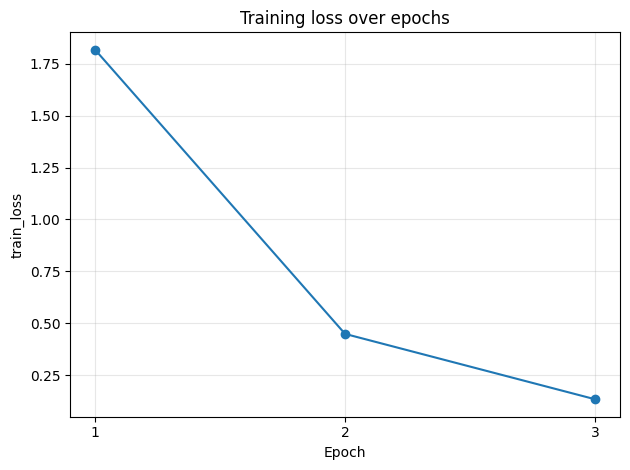

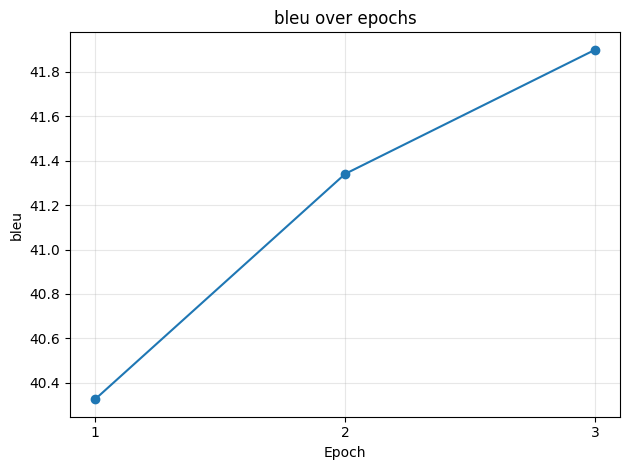

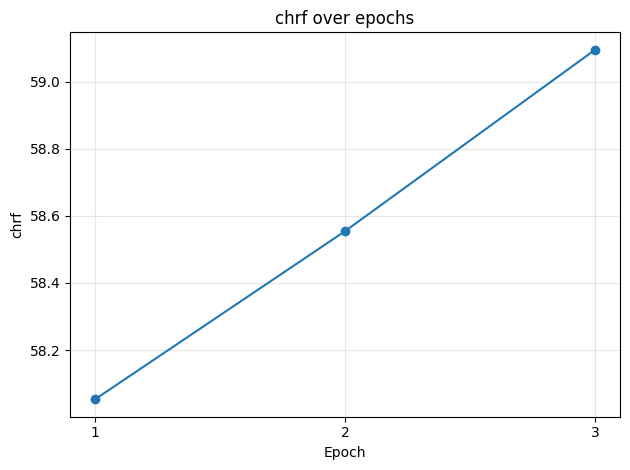

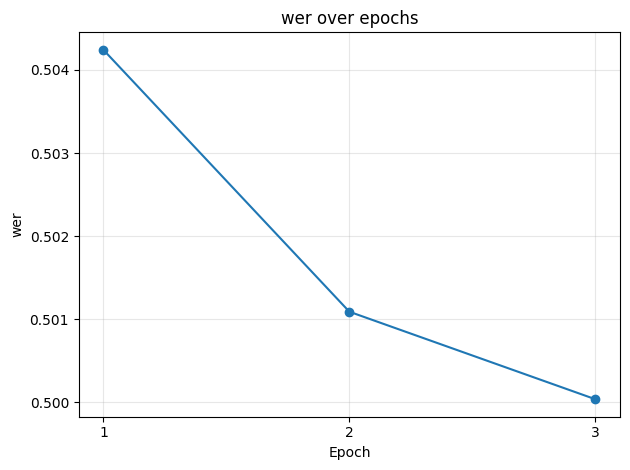

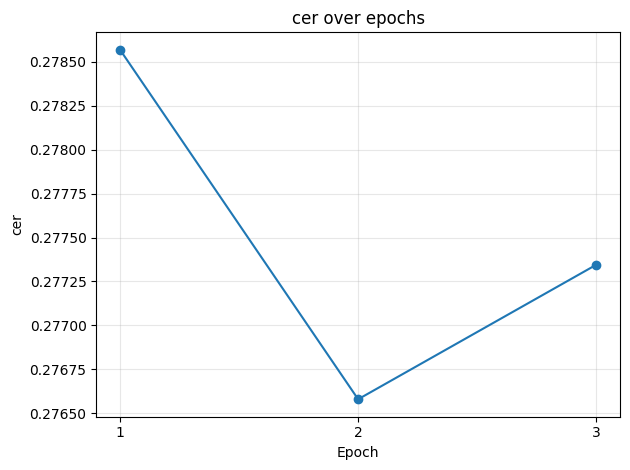

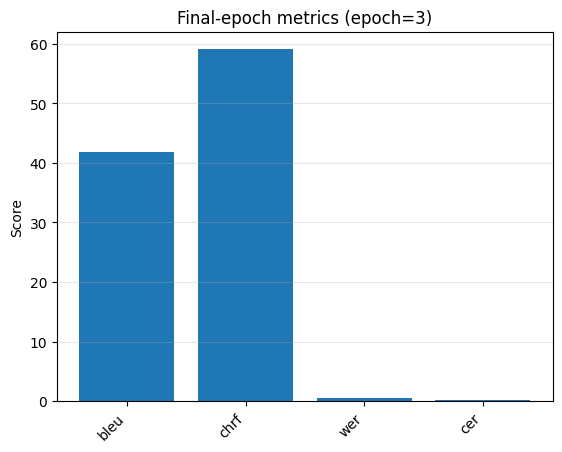

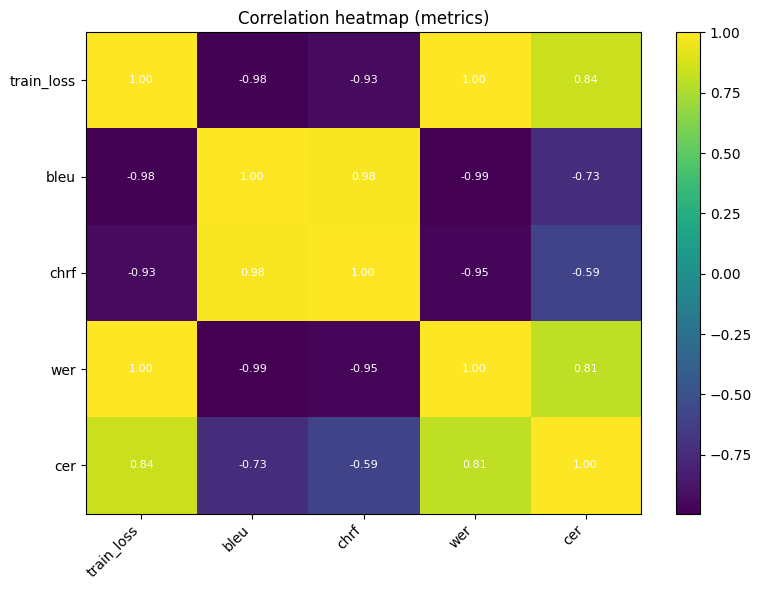

In [21]:
df = pd.read_csv(HISTORY_CSV)
metric_cols = [c for c in df.columns if c not in ["epoch", "train_loss"]]

# 1) Loss and each metric over epochs
plot_lines(df, "epoch", ["train_loss"], "Training loss over epochs", "train_loss")
for m in metric_cols:
    plot_lines(df, "epoch", [m], f"{m} over epochs", m)

# 2) Final-epoch bar chart
last = df.sort_values("epoch").iloc[-1]
plt.figure()
plt.bar(metric_cols, [float(last[m]) for m in metric_cols])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Score")
plt.title(f"Final-epoch metrics (epoch={int(last['epoch'])})")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

# 3) Correlation heatmap across metrics (epoch-wise)
corr = df[["train_loss"] + metric_cols].corr(numeric_only=True)
plot_heatmap(corr, "Correlation heatmap (metrics)")

## 6. Pairwise dialect matrix

Every ordered source → target dialect pair. The diagonal is excluded because
identity pairs were not used during training.

### 6.1 Evaluate one dialect pair

In [22]:
RAW_EVAL_DF = test_df_raw
def eval_pair_metrics(model, tokenizer, raw_df, src_key, tgt_key,
                      batch_size=EVAL_BATCH_SIZE, max_batches=None):
    pair_df = build_pair_df(raw_df, src_key, tgt_key)
    n = len(pair_df)
    if n == 0:
        return None, 0

    loader = make_loader(pair_df, tokenizer, batch_size=batch_size,
                         tag_mode="fixed", tgt_dialect=tgt_key)

    preds, refs = generate_preds(model, tokenizer, loader,
                                 max_batches=max_batches, desc=f"{src_key}->{tgt_key}")
    if len(preds) == 0:
        return None, 0

    return compute_metrics(preds, refs), n

print("Using eval split rows:", len(RAW_EVAL_DF))

Using eval split rows: 375


### 6.2 Build the matrix

In [23]:
MAX_BATCHES = None   # set 10 for a quick preview first, then None for the full run

mat = {m: np.full((len(DIALECTS), len(DIALECTS)), np.nan, dtype=float) for m in METRIC_NAMES}
nmat = np.zeros((len(DIALECTS), len(DIALECTS)), dtype=int)

for i, tgt in enumerate(DIALECTS):       # rows = target
    for j, src in enumerate(DIALECTS):   # cols = source
        if src == tgt:
            continue  # ✅ exclude same dialect pairs

        metrics, n = eval_pair_metrics(model, tokenizer, RAW_EVAL_DF, src, tgt,
                                       max_batches=MAX_BATCHES)
        nmat[i, j] = n
        clear_gpu()

        if metrics is None:
            continue
        for m in METRIC_NAMES:
            mat[m][i, j] = metrics[m]

index = [f"tgt:{d}" for d in DIALECTS]
columns = [f"src:{d}" for d in DIALECTS]

tables = {m: pd.DataFrame(mat[m], index=index, columns=columns) for m in METRIC_NAMES}
n_df = pd.DataFrame(nmat, index=index, columns=columns)

display(tables["bleu"])
display(tables["cer"])
display(n_df)

# save
for m, dfm in tables.items():
    out = f"{WORKDIR}/{m}_dialect_matrix.csv"
    dfm.to_csv(out)
    print("Saved:", out)

n_df.to_csv(f"{WORKDIR}/n_samples_dialect_matrix.csv")
print("Saved:", f"{WORKDIR}/n_samples_dialect_matrix.csv")

,src:std_bn,src:barishal,src:chittagong,src:mymensingh,src:noakhali,src:sylhet
tgt:std_bn,NaN,59.205718,47.011004,69.352036,53.120216,55.728109
tgt:barishal,60.015856,NaN,46.347886,60.583949,49.745813,51.355444
tgt:chittagong,22.458187,20.890592,NaN,21.994196,18.457638,19.881899
tgt:mymensingh,64.103249,57.302188,45.631589,NaN,50.021261,51.193056
tgt:noakhali,30.581880,28.339000,24.119206,30.615220,NaN,25.651377
tgt:sylhet,22.626725,19.459521,17.555564,22.311149,18.081429,NaN


,src:std_bn,src:barishal,src:chittagong,src:mymensingh,src:noakhali,src:sylhet
tgt:std_bn,NaN,0.143759,0.226575,0.103111,0.194174,0.175293
tgt:barishal,0.170157,NaN,0.283474,0.165923,0.258139,0.241150
tgt:chittagong,0.386789,0.408594,NaN,0.387057,0.426880,0.436820
tgt:mymensingh,0.128912,0.161947,0.256168,NaN,0.225432,0.215412
tgt:noakhali,0.305010,0.330799,0.369416,0.307884,NaN,0.368933
tgt:sylhet,0.355702,0.373395,0.438645,0.360361,0.421471,NaN


,src:std_bn,src:barishal,src:chittagong,src:mymensingh,src:noakhali,src:sylhet
tgt:std_bn,0,375,375,375,375,375
tgt:barishal,375,0,375,375,375,375
tgt:chittagong,375,375,0,375,375,375
tgt:mymensingh,375,375,375,0,375,375
tgt:noakhali,375,375,375,375,0,375
tgt:sylhet,375,375,375,375,375,0


Saved: /kaggle/working/bleu_dialect_matrix.csv
Saved: /kaggle/working/chrf_dialect_matrix.csv
Saved: /kaggle/working/wer_dialect_matrix.csv
Saved: /kaggle/working/cer_dialect_matrix.csv
Saved: /kaggle/working/n_samples_dialect_matrix.csv


### 6.3 Matrix heatmaps

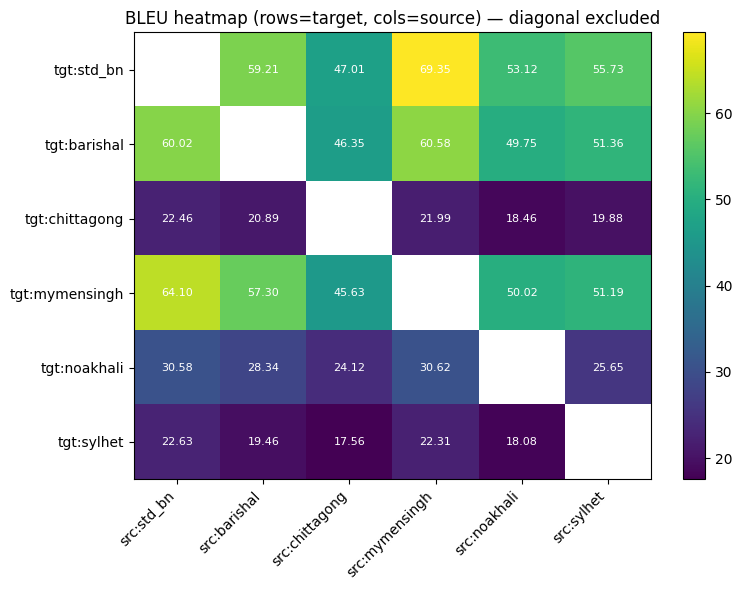

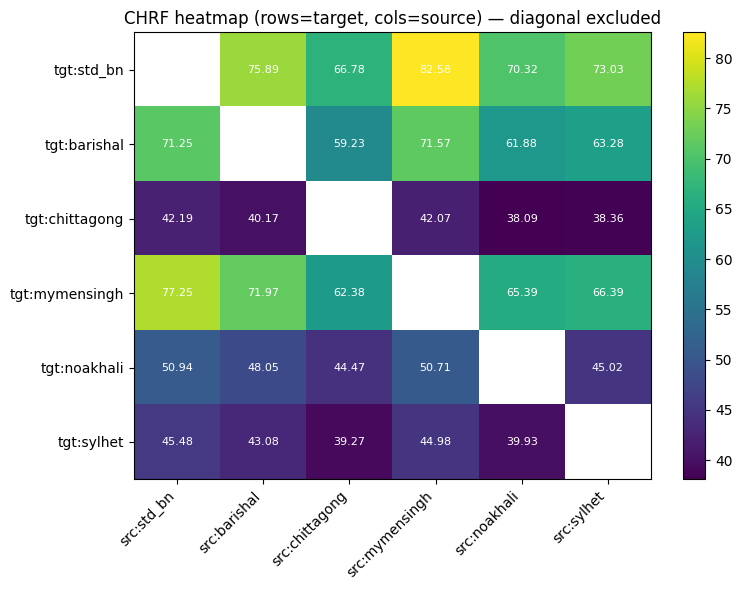

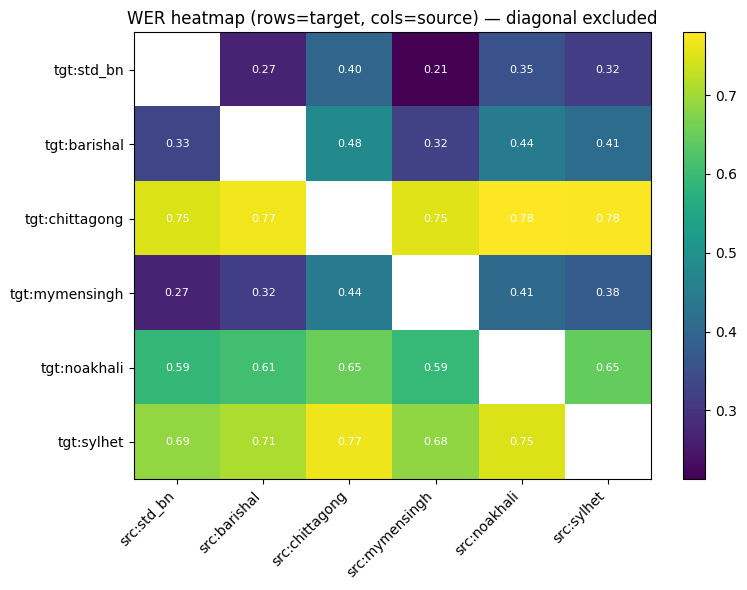

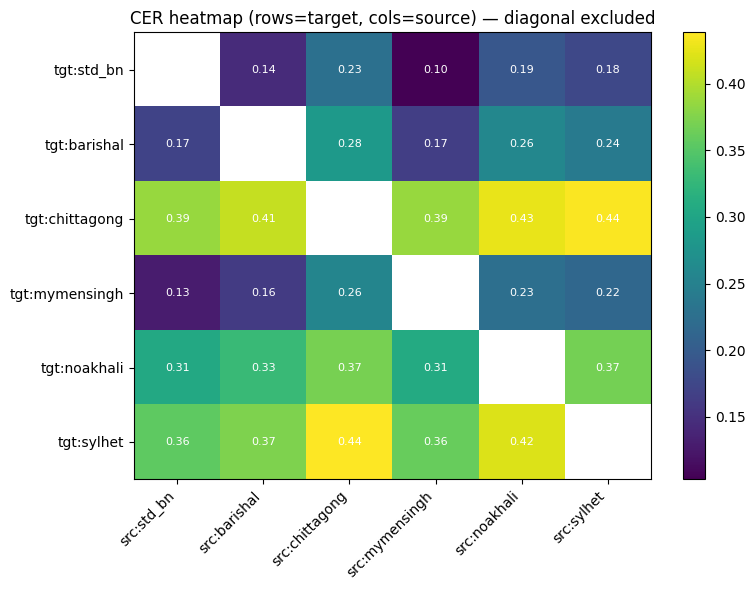

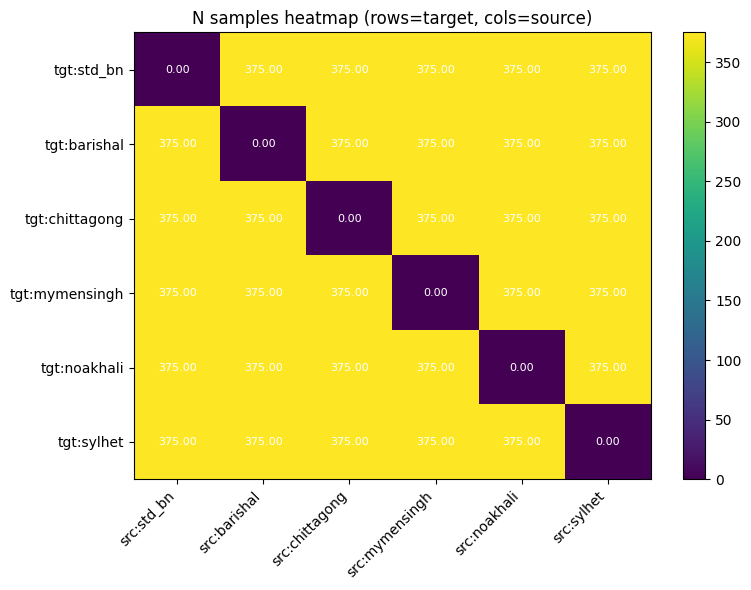

In [24]:
for m in METRIC_NAMES:
    plot_heatmap(tables[m], f"{m.upper()} heatmap (rows=target, cols=source) — diagonal excluded")

plot_heatmap(n_df, "N samples heatmap (rows=target, cols=source)")

## 7. Dialect → Standard Bangla summary

Each dialect translated into Standard Bangla, scored separately.

- **Tagged (main result):** source is prefixed with `<2std_bn>`, matching training.
- **Untagged (ablation):** no target tag, to measure how much the model relies on it.

### 7.1 Evaluate each dialect against Standard Bangla (tagged vs untagged)

In [25]:
SRC_DIALECTS = [d for d in DIALECTS if d != "std_bn"]   # skip identity pair

def eval_to_std(tag_mode):
    rows = []
    for d in SRC_DIALECTS:
        pair_df = build_pair_df(RAW_EVAL_DF, d, "std_bn")
        if tag_mode == "fixed":
            loader = make_loader(pair_df, tokenizer, batch_size=EVAL_BATCH_SIZE,
                                 tag_mode="fixed", tgt_dialect="std_bn")
        else:
            loader = make_loader(pair_df, tokenizer, batch_size=EVAL_BATCH_SIZE,
                                 tag_mode="none")

        metrics = evaluate(model, tokenizer, loader, desc=f"{d}->std_bn ({tag_mode})")
        metrics["dialect"] = d
        metrics["n_samples"] = len(pair_df)
        rows.append(metrics)
        clear_gpu()
    return pd.DataFrame(rows).set_index("dialect")


# ---- Tagged (main result) ----
result_df = eval_to_std("fixed")
print("Tagged (<2std_bn>) — main result:")
display(result_df)
result_df.to_csv(f"{WORKDIR}/dialect_summary_with_std.csv")
print("Saved:", f"{WORKDIR}/dialect_summary_with_std.csv")

# ---- Untagged (ablation) ----
untagged_df = eval_to_std("none")
print("Untagged — ablation:")
display(untagged_df)
untagged_df.to_csv(f"{WORKDIR}/dialect_summary_untagged.csv")
print("Saved:", f"{WORKDIR}/dialect_summary_untagged.csv")

# ---- Side-by-side comparison ----
compare_df = pd.concat(
    {"tagged": result_df[METRIC_NAMES], "untagged": untagged_df[METRIC_NAMES]},
    axis=1,
)
for m in METRIC_NAMES:
    compare_df[("delta", m)] = result_df[m] - untagged_df[m]   # tagged minus untagged

compare_df.loc["mean"] = compare_df.mean()
print("Tagged vs untagged (delta = tagged − untagged):")
display(compare_df.round(4))
compare_df.to_csv(f"{WORKDIR}/dialect_summary_tag_ablation.csv")
print("Saved:", f"{WORKDIR}/dialect_summary_tag_ablation.csv")

Tagged (<2std_bn>) — main result:


,bleu,chrf,wer,cer,n_samples
dialect,,,,,
barishal,59.205718,75.888540,0.267424,0.143759,375
chittagong,47.011004,66.777577,0.398897,0.226575,375
mymensingh,69.352036,82.582517,0.212542,0.103111,375
noakhali,53.120216,70.315891,0.354896,0.194174,375
sylhet,55.728109,73.030758,0.315827,0.175293,375


Saved: /kaggle/working/dialect_summary_with_std.csv


Untagged — ablation:


,bleu,chrf,wer,cer,n_samples
dialect,,,,,
barishal,17.589755,44.601506,0.626738,0.323336,375
chittagong,15.036033,40.309831,0.693460,0.386993,375
mymensingh,21.408474,47.959303,0.582194,0.294808,375
noakhali,16.794551,41.520241,0.680320,0.368755,375
sylhet,16.877992,42.572915,0.644124,0.355567,375


Saved: /kaggle/working/dialect_summary_untagged.csv
Tagged vs untagged (delta = tagged − untagged):


tagged                          untagged                   \
               bleu     chrf     wer     cer     bleu     chrf     wer   
dialect                                                                  
barishal    59.2057  75.8885  0.2674  0.1438  17.5898  44.6015  0.6267   
chittagong  47.0110  66.7776  0.3989  0.2266  15.0360  40.3098  0.6935   
mymensingh  69.3520  82.5825  0.2125  0.1031  21.4085  47.9593  0.5822   
noakhali    53.1202  70.3159  0.3549  0.1942  16.7946  41.5202  0.6803   
sylhet      55.7281  73.0308  0.3158  0.1753  16.8780  42.5729  0.6441   
mean        56.8834  73.7191  0.3099  0.1686  17.5414  43.3928  0.6454   

                      delta                           
               cer     bleu     chrf     wer     cer  
dialect                                               
barishal    0.3233  41.6160  31.2870 -0.3593 -0.1796  
chittagong  0.3870  31.9750  26.4677 -0.2946 -0.1604  
mymensingh  0.2948  47.9436  34.6232 -0.3697 -0.1917  
noakhali    0.3688  36.3257  28.7957 -0.3254 -0.1746  
sylhet      0.3556  38.8501  30.4578 -0.3283 -0.1803  
mean        0.3459  39.3421  30.3263 -0.3355 -0.1773

Saved: /kaggle/working/dialect_summary_tag_ablation.csv


### 7.2 Dialect-wise bar charts

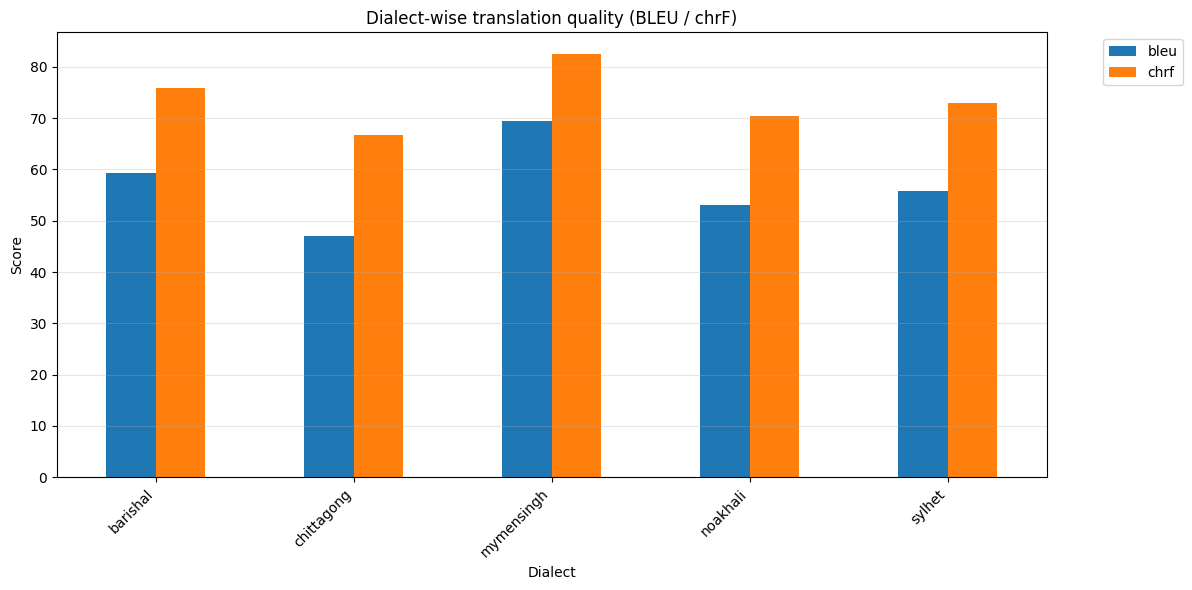

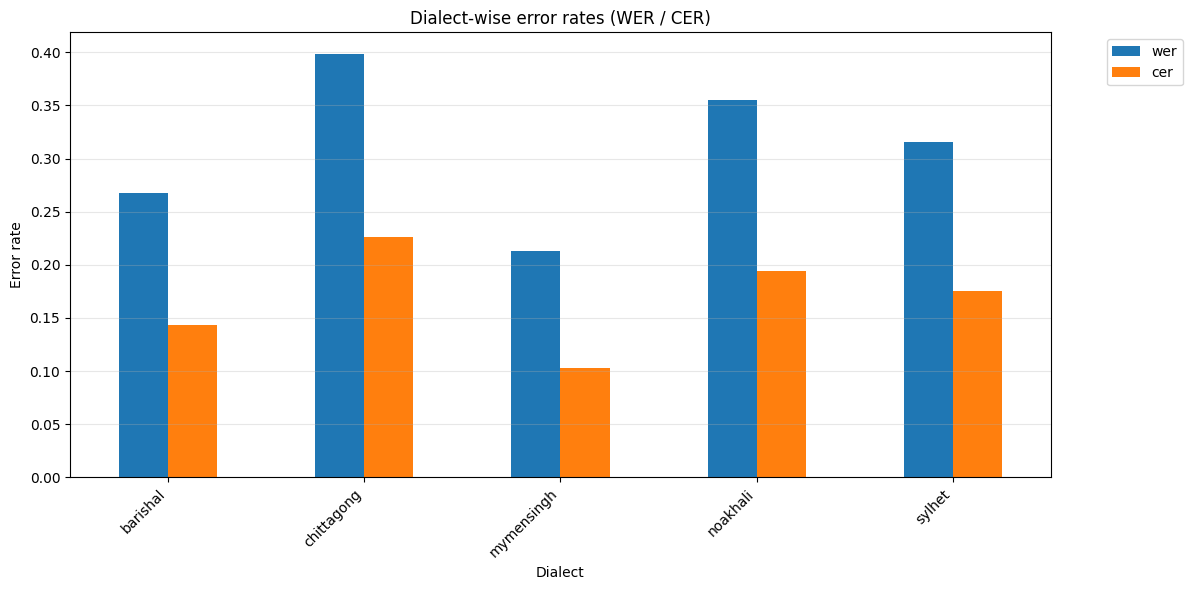

In [26]:
plot_bars(result_df, ["bleu", "chrf"], "Dialect-wise translation quality (BLEU / chrF)")
plot_bars(result_df, ["wer", "cer"], "Dialect-wise error rates (WER / CER)", ylabel="Error rate")

### Redraw and save all plots

Saved: /kaggle/working/plots/train_loss.png


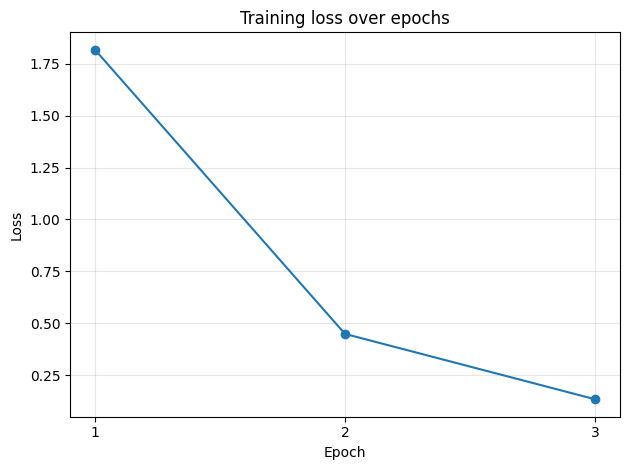

Saved: /kaggle/working/plots/val_bleu_curve.png


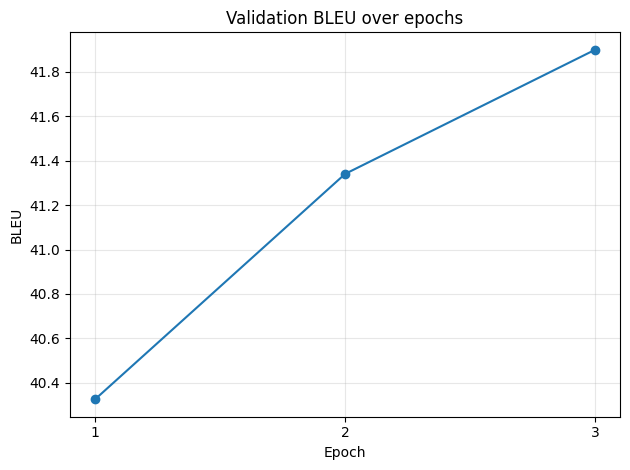

Saved: /kaggle/working/plots/val_chrf_curve.png


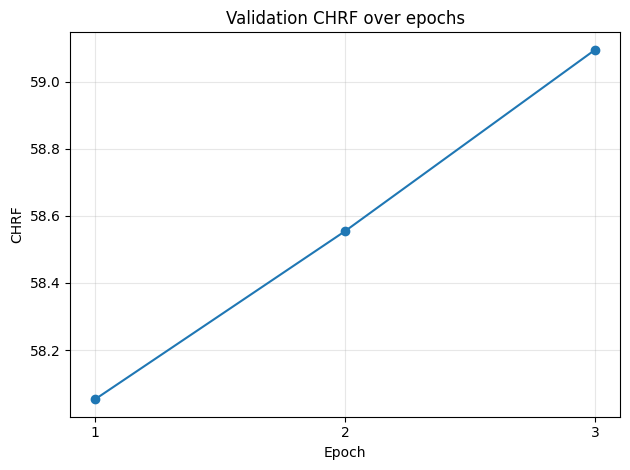

Saved: /kaggle/working/plots/val_wer_curve.png


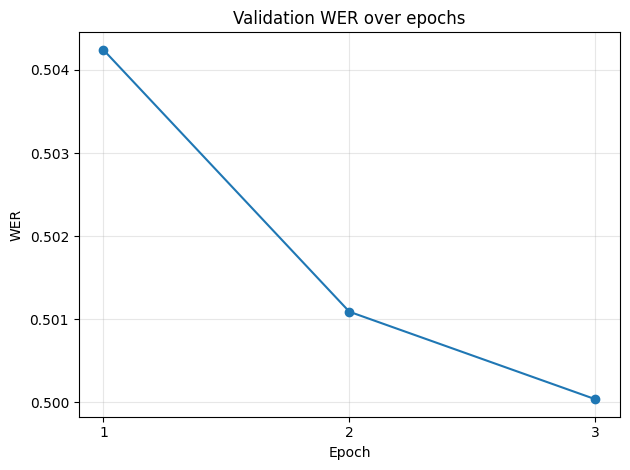

Saved: /kaggle/working/plots/val_cer_curve.png


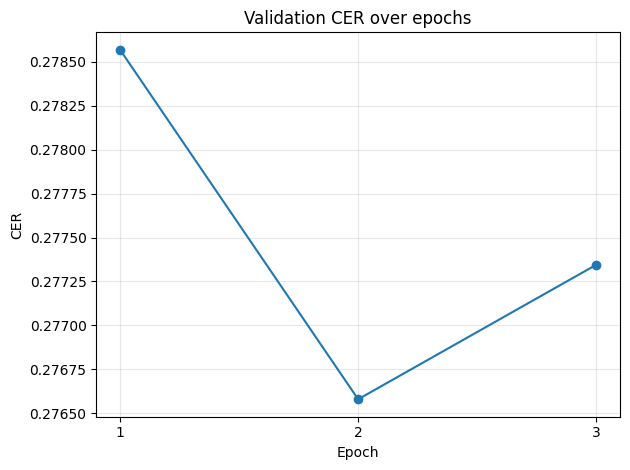

Saved: /kaggle/working/plots/heatmap_bleu.png


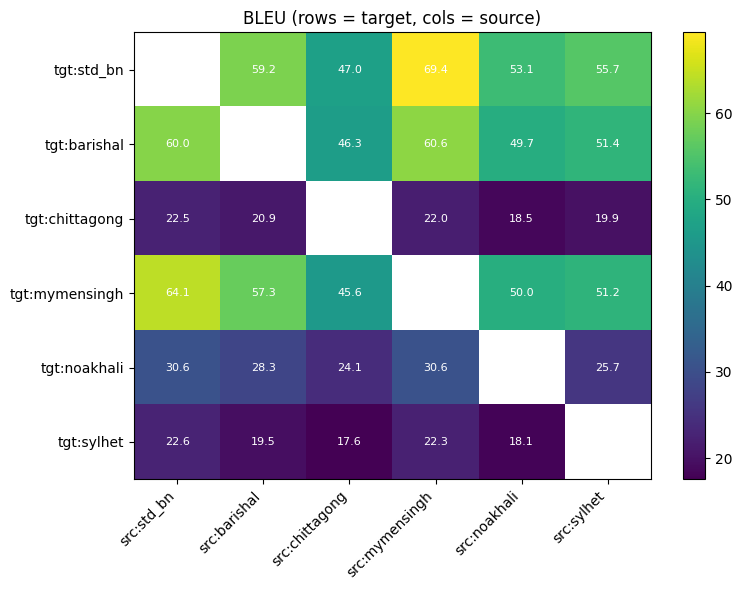

Saved: /kaggle/working/plots/heatmap_chrf.png


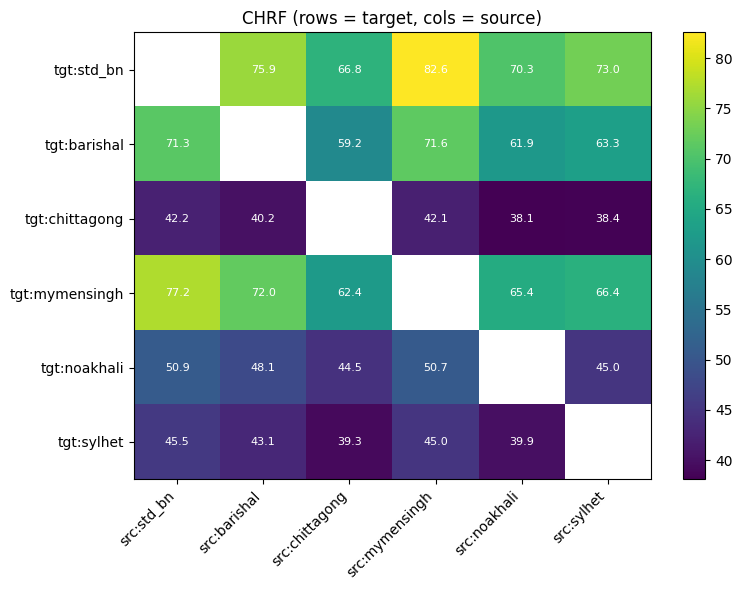

Saved: /kaggle/working/plots/heatmap_wer.png


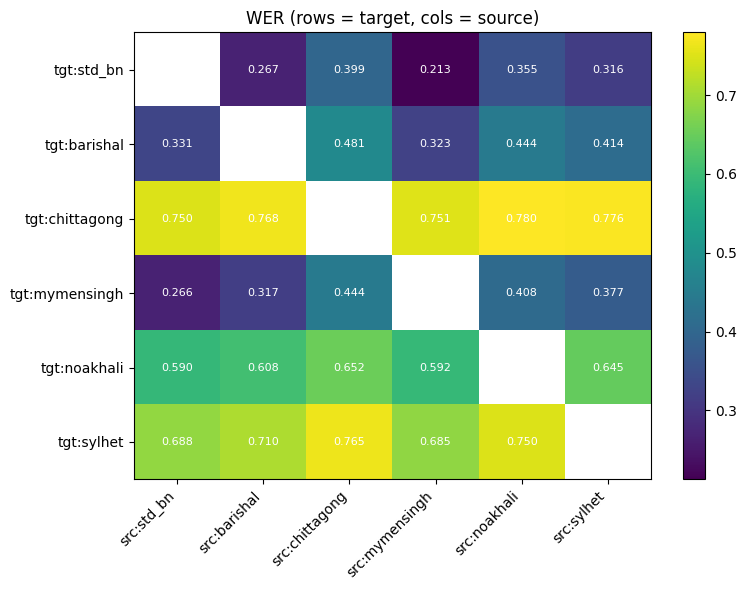

Saved: /kaggle/working/plots/heatmap_cer.png


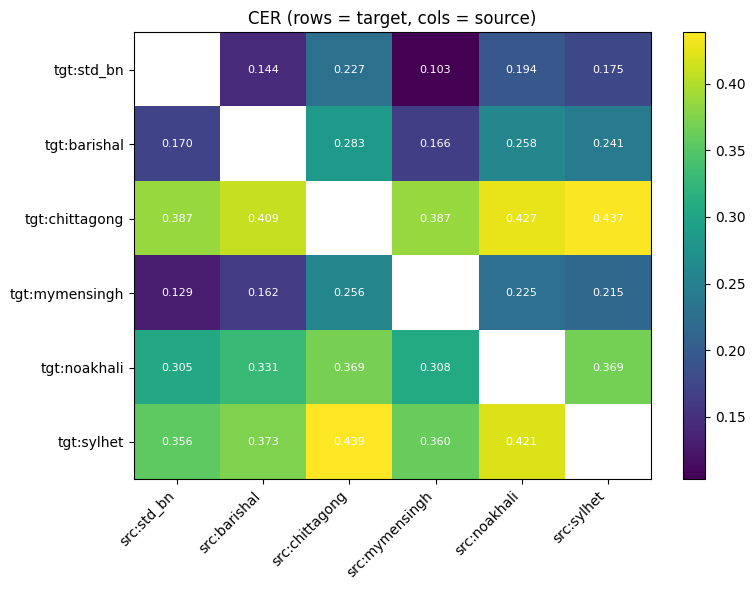

Saved: /kaggle/working/plots/to_std_bleu_chrf.png


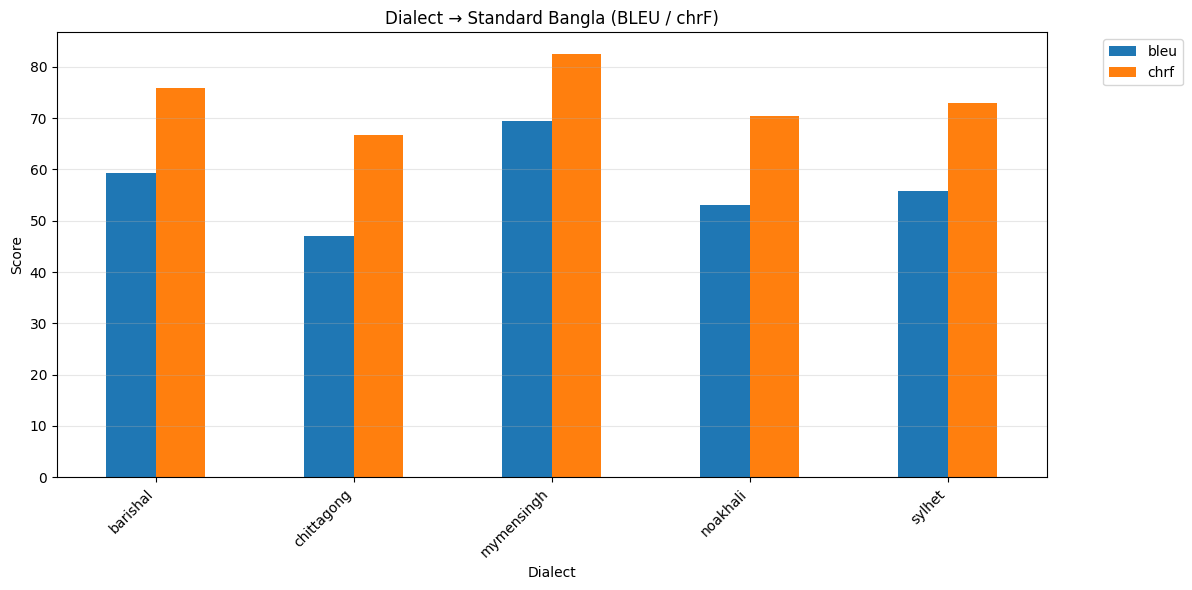

Saved: /kaggle/working/plots/to_std_wer_cer.png


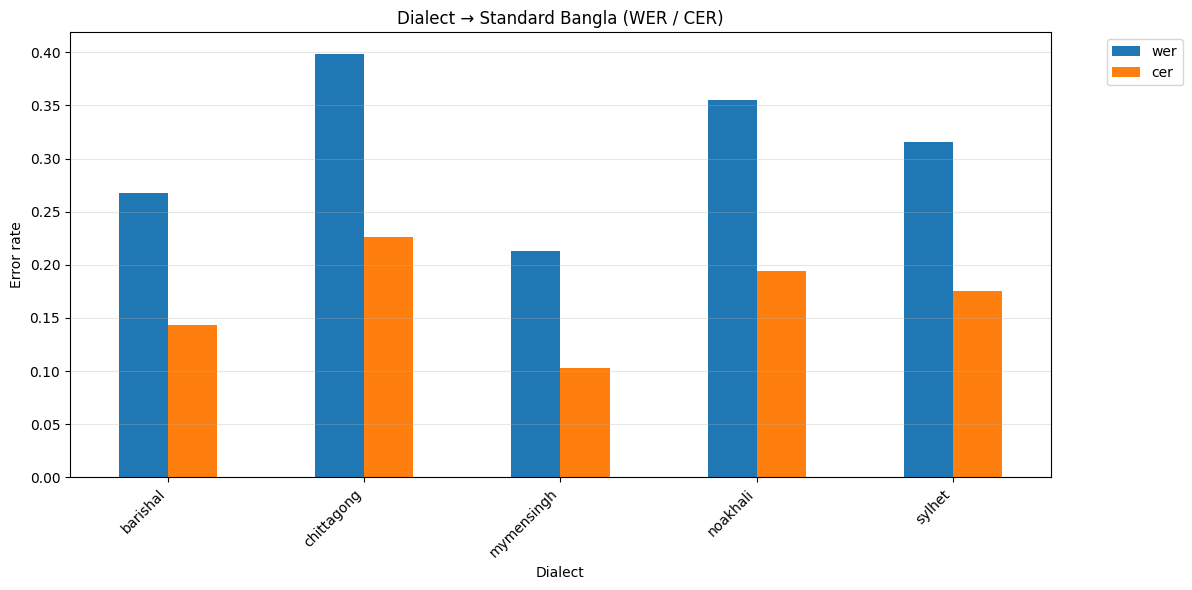

Zipped: /kaggle/working/plots.zip


In [27]:
# ---- 5.3 Training curves ----
hist = pd.read_csv(HISTORY_CSV)
plot_lines(hist, "epoch", ["train_loss"], "Training loss over epochs", "Loss", save="train_loss")
for m in METRIC_NAMES:
    plot_lines(hist, "epoch", [m], f"Validation {m.upper()} over epochs", m.upper(), save=f"val_{m}_curve")

# ---- 6.3 Pairwise dialect heatmaps ----
for m in METRIC_NAMES:
    t = pd.read_csv(f"{WORKDIR}/{m}_dialect_matrix.csv", index_col=0)
    plot_heatmap(t, f"{m.upper()} (rows = target, cols = source)",
                 save=f"heatmap_{m}", fmt=".1f" if m in ("bleu", "chrf") else ".3f")

# ---- 7.2 Dialect → Standard Bangla bars ----
summary_csv = f"{WORKDIR}/dialect_summary_with_std.csv"
if os.path.exists(summary_csv):
    res = pd.read_csv(summary_csv, index_col=0)
    plot_bars(res, ["bleu", "chrf"], "Dialect → Standard Bangla (BLEU / chrF)", save="to_std_bleu_chrf")
    plot_bars(res, ["wer", "cer"], "Dialect → Standard Bangla (WER / CER)",
              ylabel="Error rate", save="to_std_wer_cer")

# ---- Zip everything for one download ----
shutil.make_archive(f"{WORKDIR}/plots", "zip", PLOT_DIR)
print("Zipped:", f"{WORKDIR}/plots.zip")

In [28]:
"""Copy baseline for cross-dialectal translation."""
!pip install -q sacrebleu
import os, itertools
import pandas as pd
import numpy as np
import sacrebleu

CSV = ("/kaggle/input/datasets/tasfiaisrat/unified-bangla-qpain/"
       "Unified_validation_dataset.csv")

DIALECT_MAP = {
    "std_bn": "bangla_speech",
    "barishal": "barishal_bangla_speech",
    "chittagong": "chittagong_bangla_speech",
    "mymensingh": "mymensingh_bangla_speech",
    "noakhali": "noakhali_bangla_speech",
    "sylhet": "sylhet_bangla_speech",
}
D = list(DIALECT_MAP)

MODEL_BLEU = {
 "std_bn":    {"barishal":52.13,"chittagong":45.72,"mymensingh":57.49,"noakhali":45.00,"sylhet":49.04},
 "barishal":  {"std_bn":55.02,"chittagong":48.35,"mymensingh":55.48,"noakhali":47.23,"sylhet":49.14},
 "chittagong":{"std_bn":39.03,"barishal":35.09,"mymensingh":38.52,"noakhali":34.09,"sylhet":35.50},
 "mymensingh":{"std_bn":55.60,"barishal":49.33,"chittagong":43.46,"noakhali":43.87,"sylhet":44.68},
 "noakhali":  {"std_bn":35.03,"barishal":31.94,"chittagong":31.80,"mymensingh":34.48,"sylhet":29.54},
 "sylhet":    {"std_bn":38.01,"barishal":35.22,"chittagong":32.50,"mymensingh":37.23,"noakhali":32.63},
}
MODEL_CHRF = {
 "std_bn":    {"barishal":73.40,"chittagong":68.87,"mymensingh":77.40,"noakhali":67.28,"sylhet":70.88},
 "barishal":  {"std_bn":68.19,"chittagong":61.32,"mymensingh":68.31,"noakhali":60.47,"sylhet":62.27},
 "chittagong":{"std_bn":52.34,"barishal":47.81,"mymensingh":51.91,"noakhali":47.16,"sylhet":48.51},
 "mymensingh":{"std_bn":72.61,"barishal":66.43,"chittagong":62.78,"noakhali":62.80,"sylhet":63.71},
 "noakhali":  {"std_bn":53.54,"barishal":49.96,"chittagong":49.44,"mymensingh":53.04,"sylhet":47.84},
 "sylhet":    {"std_bn":55.91,"barishal":52.82,"chittagong":50.49,"mymensingh":54.88,"noakhali":49.85},
}

df = pd.read_csv(CSV)
missing = [c for c in DIALECT_MAP.values() if c not in df.columns]
if missing:
    raise SystemExit(f"columns not found: {missing}\navailable: {list(df.columns)}")
print(f"{CSV.split('/')[-1]}: {len(df)} sentences\n")

rows = []
for tgt, src in itertools.product(D, D):
    if tgt == src:
        continue
    s = df[DIALECT_MAP[src]].fillna("").astype(str).str.strip().tolist()
    r = df[DIALECT_MAP[tgt]].fillna("").astype(str).str.strip().tolist()
    keep = [(a, b) for a, b in zip(s, r) if a and b]
    hyp = [a for a, _ in keep]; ref = [b for _, b in keep]
    rows.append({
        "target": tgt, "source": src, "n": len(keep),
        "copy_bleu": sacrebleu.corpus_bleu(hyp, [ref], tokenize="char").score,
        "copy_chrf": sacrebleu.corpus_chrf(hyp, [ref]).score,
        "model_bleu": MODEL_BLEU.get(tgt, {}).get(src),
        "model_chrf": MODEL_CHRF.get(tgt, {}).get(src)})

out = pd.DataFrame(rows)
out["bleu_gain"] = out.model_bleu - out.copy_bleu
out["chrf_gain"] = out.model_chrf - out.copy_chrf
out.to_csv("/kaggle/working/copy_baseline.csv", index=False)

print(f"{'pair':28s}{'copy':>18s}{'model':>18s}{'gain':>18s}")
print(f"{'':28s}{'BLEU':>8s}{'chrF':>10s}{'BLEU':>8s}{'chrF':>10s}{'BLEU':>8s}{'chrF':>10s}")
print("-" * 82)
for _, r in out.sort_values("chrf_gain").iterrows():
    flag = "   <-- MODEL LOSES" if r.chrf_gain < 0 else ""
    print(f"{r.source+' -> '+r.target:28s}{r.copy_bleu:8.2f}{r.copy_chrf:10.2f}"
          f"{r.model_bleu:8.2f}{r.model_chrf:10.2f}"
          f"{r.bleu_gain:+8.2f}{r.chrf_gain:+10.2f}{flag}")

print("-" * 82)
print(f"{'MEAN':28s}{out.copy_bleu.mean():8.2f}{out.copy_chrf.mean():10.2f}"
      f"{out.model_bleu.mean():8.2f}{out.model_chrf.mean():10.2f}"
      f"{out.bleu_gain.mean():+8.2f}{out.chrf_gain.mean():+10.2f}")

lose = out[out.chrf_gain < 0]
print(f"\npairs where copying beats the model (chrF): {len(lose)} of {len(out)}")
if len(lose):
    for _, r in lose.iterrows():
        print(f"   {r.source} -> {r.target}: copy {r.copy_chrf:.2f} vs model {r.model_chrf:.2f}")
else:
    print("   none -- the model clears the copy baseline on every direction")
print("\nwrote /kaggle/working/copy_baseline.csv")

Unified_validation_dataset.csv: 250 sentences

pair                                      copy             model              gain
                                BLEU      chrF    BLEU      chrF    BLEU      chrF
----------------------------------------------------------------------------------
mymensingh -> sylhet           49.56     42.67   37.23     54.88  -12.33    +12.21
barishal -> noakhali           40.13     35.75   31.94     49.96   -8.19    +14.21
mymensingh -> noakhali         44.70     38.42   34.48     53.04  -10.22    +14.62
std_bn -> mymensingh           64.05     57.24   55.60     72.61   -8.45    +15.37
sylhet -> noakhali             35.31     30.48   29.54     47.84   -5.77    +17.36
std_bn -> noakhali             41.55     35.99   35.03     53.54   -6.52    +17.55
noakhali -> chittagong         32.71     28.85   34.09     47.16   +1.38    +18.31
std_bn -> sylhet               43.17     37.22   38.01     55.91   -5.16    +18.69
mymensingh -> std_bn           63.94    

## 8. Appendix — disk cleanup

### 8.1 Delete checkpoints and archives (keeps the best model and the CSVs)

In [29]:
# Delete per-epoch checkpoints (largest)
for p in glob.glob(f"{WORKDIR}/checkpoint_epoch*"):
    shutil.rmtree(p, ignore_errors=True)

# Delete large archives if created
for p in glob.glob(f"{WORKDIR}/*.tar") + glob.glob(f"{WORKDIR}/*.tar.gz"):
    try:
        os.remove(p)
    except Exception as e:
        print(f"Failed to delete {p}: {e}")

# Optional: delete HF caches inside working if you created them
shutil.rmtree(f"{WORKDIR}/hf", ignore_errors=True)

print("✅ Cleanup done")
!df -h /kaggle/working

✅ Cleanup done
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  2.3G   18G  12% /kaggle/working
